# Exploração dos resultados do E1

Tabelas e figuras para o relatório individual do E1 (IAG 2026/27, Projeto 1: resíduos e economia circular em Guimarães).

- Só lê ficheiros que já existem (`kb/E1`, `tests/questions_E1.jsonl` e `experiments/E1`). Não corre modelos nem juízes.
- Tudo é sobre o E1, exceto a secção 3 (escolha do embedding no grupo).
- Em cada secção há uma tabela, o gráfico e uma linha a dizer o que ele mostra.
- As figuras guardam-se em `docs/figuras/` com a função da secção 8, só as que estiverem marcadas.

Para abrir, na raiz do repositório:

```
.venv\Scripts\python -m jupyterlab analise/exploracao.ipynb
```

Para correr tudo sem abrir (refaz as tabelas e as figuras dentro do notebook):

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace analise/exploracao.ipynb
```

Assim usa o Python do `.venv`; o `jupyter` sozinho pode ir buscar outra instalação.

In [1]:
import io
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib import font_manager
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator, ScalarFormatter

# Raiz do repositório: o notebook pode abrir-se a partir de analise/ ou da raiz.
RAIZ = Path.cwd().resolve()
while not (RAIZ / "rag" / "comum.py").exists():
    if RAIZ.parent == RAIZ:
        raise FileNotFoundError("Não encontrei a raiz do repositório (a pasta com rag/comum.py).")
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "rag"))
import comum      # caminhos, catálogo e leitura de JSONL
import metricas   # a regra de acerto do E1 (e a do E2)

EXP = RAIZ / "experiments" / "E1"
FIGURAS = RAIZ / "docs" / "figuras"


def le_json(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))


PERGUNTAS = {q["id"]: q for q in comum.le_jsonl(comum.PERGUNTAS)}
TIPOS = {"factual": "factual", "multi_doc": "multi_doc", "unanswerable": "sem resposta"}
print(f"Python {sys.version.split()[0]} em {Path(sys.prefix).name}; repositório: {RAIZ.name}\n{len(PERGUNTAS)} perguntas: " +
      ", ".join(f"{sum(q['type'] == t for q in PERGUNTAS.values())} {n}" for t, n in TIPOS.items()))

Python 3.11.9 em .venv; repositório: iag-projeto1-e1
15 perguntas: 8 factual, 4 multi_doc, 3 sem resposta


In [2]:
# --- Cores: a paleta categórica validada (8 cores, ordem fixa). Cada modelo tem sempre a mesma cor.
# Os embeddings e os LLM nunca aparecem na mesma figura, por isso cada família usa as cores pela mesma ordem.
COR_EMB = {"qwen3-embedding-8b": "#2a78d6", "qwen3-embedding-4b": "#eb6834", "qwen3-embedding-0.6b": "#1baf7a",
           "bge-m3": "#eda100", "embeddinggemma": "#e87ba4", "embeddinggemma-sem-prefixos": "#008300",
           "embeddinggemma-titulo": "#6250d6"}
NOME_EMB = {"qwen3-embedding-8b": "Qwen3-Embedding 8B", "qwen3-embedding-4b": "Qwen3-Embedding 4B",
            "qwen3-embedding-0.6b": "Qwen3-Embedding 0.6B", "bge-m3": "bge-m3", "embeddinggemma": "EmbeddingGemma",
            "embeddinggemma-sem-prefixos": "EmbeddingGemma sem prefixos", "embeddinggemma-titulo": "EmbeddingGemma com título"}
CURTO_EMB = {"qwen3-embedding-8b": "Qwen3 8B", "qwen3-embedding-4b": "Qwen3 4B", "qwen3-embedding-0.6b": "Qwen3 0.6B",
             "bge-m3": "bge-m3", "embeddinggemma": "EGemma", "embeddinggemma-sem-prefixos": "EGemma\nsem prefixos",
             "embeddinggemma-titulo": "EGemma\ncom título"}
MODELOS_EMB = list(COR_EMB)

COR_LLM = {"gemma4-12b": "#2a78d6", "qwen3.5-9b": "#eb6834", "amalia-9b": "#1baf7a", "ministral-3-14b": "#eda100"}
NOME_LLM = {"gemma4-12b": "Gemma 4 12B", "qwen3.5-9b": "Qwen3.5 9B", "amalia-9b": "AMALIA 9B", "ministral-3-14b": "Ministral 3 14B"}
CURTO_LLM = {"gemma4-12b": "Gemma 4", "qwen3.5-9b": "Qwen3.5", "amalia-9b": "AMALIA", "ministral-3-14b": "Ministral"}
LLMS = list(COR_LLM)
JUIZES = ["gpt-oss-120b", "gpt-oss-20b"]
CONFIGS = ["A", "B", "C"]
DESCR_CONFIG = {"A": "A: excertos de 500 tokens, pesquisa densa", "B": "B: excertos de 200 tokens, pesquisa densa",
                "C": "C: excertos de 500 tokens, pesquisa híbrida (densa + BM25, RRF)"}

# Tons para o que não é um modelo (âmbito dos documentos) e escala sequencial (azul, do claro ao escuro).
COR_AMBITO = {"Guimarães": "#52514e", "Nacional": "#a8a69e"}
AZUL = {100: "#cde2fb", 250: "#86b6ef", 350: "#5598e7", 450: "#2a78d6", 550: "#1c5cab", 650: "#104281"}
NEUTRO = "#f0efec"


def _fonte():
    disponiveis = {f.name for f in font_manager.fontManager.ttflist}
    return next(n for n in ("NewsGotT", "Segoe UI", "Arial", "DejaVu Sans") if n in disponiveis)


mpl.rcParams.update({
    "font.family": _fonte(), "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "figure.dpi": 110, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "legend.frameon": False,
    "hatch.linewidth": 0.8, "pdf.fonttype": 42, "axes.unicode_minus": True,
})
LARGURA = 16 / 2.54  # largura do texto numa A4 com margens de 2,5 cm, em polegadas
print("Letra das figuras:", mpl.rcParams["font.family"][0])


# --- Números em português: vírgula decimal e espaço nos milhares.
def num(x, casas=3, sinal=False):
    if x is None or (isinstance(x, (float, np.floating)) and np.isnan(x)):
        return "—"
    s = f"{x:{'+' if sinal else ''},.{casas}f}".replace(",", " ").replace(".", ",")
    return s.replace("-", "−")


class Virgula(ScalarFormatter):
    def __call__(self, x, pos=None):
        return super().__call__(x, pos).replace(".", ",")


def virgula(ax, eixos="y", casas=None):
    for e in eixos:
        eixo = getattr(ax, f"{e}axis")
        eixo.set_major_formatter(FuncFormatter(lambda v, p, c=casas: num(v, c)) if casas is not None
                                 else Virgula(useOffset=False))


def escala(ax, lim=None, inteiros=False):
    # Eixo y: notas de 0 a 2 de 0,5 em 0,5; proporções de 0 a 1 de 0,2 em 0,2; contagens só com inteiros.
    if lim:
        ax.set_ylim(*lim)
        passo = {2: 0.5, 1: 0.2}.get(lim[1], 1)
        ax.set_yticks(np.arange(lim[0], lim[1] + 1e-9, passo))
        virgula(ax, casas=1 if passo < 1 else 0)
    elif inteiros:
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        virgula(ax, casas=0)
    else:
        virgula(ax)


def tabela(df, casas=3, por_coluna=None, legenda=None):
    # Tabela com vírgula decimal: inteiros sem casas, reais com `casas` (ou as de `por_coluna`).
    def f(v, c=casas):
        if isinstance(v, (bool, np.bool_)):
            return "sim" if v else "não"
        if isinstance(v, (int, np.integer)):
            return num(v, 0)
        if isinstance(v, (float, np.floating)):
            return num(v, c)
        return "—" if v is None else v
    s = df.style.format(f)
    for col, c in (por_coluna or {}).items():
        s = s.format(lambda v, c=c: f(v, c), subset=[col])
    return s.set_caption(legenda) if legenda else s


# --- Figuras que se podem exportar (secção 8).
FIGURAS_FEITAS = {}


def regista(fig, nome):
    FIGURAS_FEITAS[nome] = fig
    return fig


def mistura(cor, branco=0.45):
    r, g, b = to_rgb(cor)
    return (r + (1 - r) * branco, g + (1 - g) * branco, b + (1 - b) * branco)


def barras(ax, grupos, series, valor, cor, nome, largura=0.84, tracejado=None):
    # Barras agrupadas: um grupo por elemento de `grupos`, uma barra por série; valor(s, g) dá o número.
    # tracejado(s, g) -> True põe riscas brancas na barra (por exemplo, resultados provisórios).
    x = np.arange(len(grupos))
    w = largura / len(series)
    for i, s in enumerate(series):
        for k, g in enumerate(grupos):
            v = valor(s, g)
            if v is None or np.isnan(v):
                continue
            riscas = bool(tracejado and tracejado(s, g))
            ax.bar(x[k] - largura / 2 + w * (i + 0.5), v, width=w * 0.88, color=cor[s], edgecolor="white",
                   linewidth=0.6, hatch="////" if riscas else None, label=nome[s] if k == 0 else None)
    ax.set_xticks(x, grupos)
    ax.grid(axis="x", visible=False)
    return ax


def legenda_modelos(fig, series, cor, nome, ncol=4, extra=()):
    pegas = [Patch(facecolor=cor[s], label=nome[s]) for s in series] + list(extra)
    fig.legend(handles=pegas, loc="outside lower center", ncol=ncol, handlelength=1.2, columnspacing=1.2)

Letra das figuras: Segoe UI


## 1. Base de conhecimento

Palavras e excertos por documento nas configurações A (500 tokens, sobreposição de 50) e B (200 tokens, sobreposição de 20).

- Os documentos de Guimarães têm os números E1-001 a E1-029, e os nacionais E1-101 a E1-126 (`docs/processo_E1.md`).
- As palavras contam-se como no `kb/E1/relatorio_palavras.csv` (texto separado por espaços); os tokens, com o tokenizador do bge-m3.

In [3]:
cat = pd.DataFrame(comum.le_catalogo())
cat["ambito"] = np.where(cat["doc_id"].str[3:].astype(int) < 100, "Guimarães", "Nacional")
cat["palavras"] = [len((RAIZ / f).read_text(encoding="utf-8").split()) for f in cat["text_file"]]
excertos = {c: pd.DataFrame(comum.le_jsonl(EXP / f"excertos_{c}.jsonl")) for c in "AB"}
for c, d in excertos.items():
    cat[f"excertos_{c}"] = cat["doc_id"].map(d.groupby("doc_id").size()).fillna(0).astype(int)
    d["ambito"] = d["doc_id"].map(cat.set_index("doc_id")["ambito"])


def resumo_base(d, e):
    linha = {"Documentos": len(d), "Palavras": int(d["palavras"].sum()), "Palavras por documento (média)": d["palavras"].mean()}
    for c in "AB":
        linha[f"Excertos {c}"] = int(d[f"excertos_{c}"].sum())
        linha[f"Excertos {c} por documento (média)"] = d[f"excertos_{c}"].mean()
        linha[f"Tokens por excerto {c} (média)"] = e[c]["tokens"].mean()
    return linha


t1 = pd.DataFrame({a: resumo_base(cat[cat["ambito"] == a], {c: excertos[c][excertos[c]["ambito"] == a] for c in "AB"})
                   for a in ["Guimarães", "Nacional"]} | {"Total": resumo_base(cat, excertos)}).T
t1 = t1.astype({k: int for k in ["Documentos", "Palavras", "Excertos A", "Excertos B"]})
tabela(t1, casas=1, legenda="Base do E1 por âmbito")

,Documentos,Palavras,Palavras por documento (média),Excertos A,Excertos A por documento (média),Tokens por excerto A (média),Excertos B,Excertos B por documento (média),Tokens por excerto B (média)
Guimarães,21,104 017,"4 953,2",378,"18,0","467,4",966,"46,0","176,9"
Nacional,15,112 255,"7 483,7",396,"26,4","462,9",1 048,"69,9","170,5"
Total,36,216 272,"6 007,6",774,"21,5","465,1",2 014,"55,9","173,6"


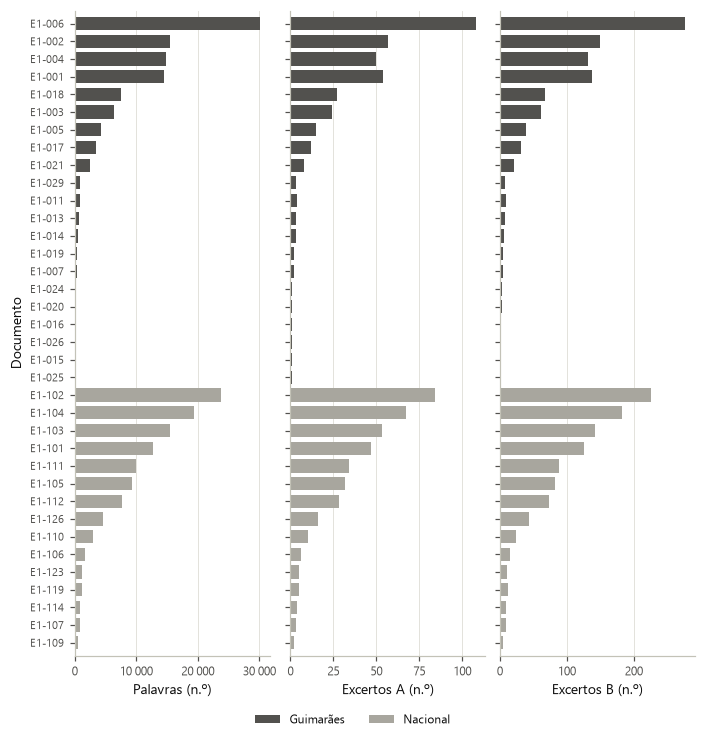

In [4]:
ordem = cat.sort_values(["ambito", "palavras"], ascending=[False, True])
fig, eixos = plt.subplots(1, 3, figsize=(LARGURA, 6.6), sharey=True, layout="constrained")
for ax, (col, rotulo) in zip(eixos, [("palavras", "Palavras (n.º)"), ("excertos_A", "Excertos A (n.º)"),
                                     ("excertos_B", "Excertos B (n.º)")]):
    ax.barh(ordem["doc_id"], ordem[col], color=ordem["ambito"].map(COR_AMBITO), height=0.75)
    ax.set_xlabel(rotulo)
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=7)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: num(v, 0)))
    ax.margins(y=0.01)
eixos[0].set_ylabel("Documento")
fig.legend(handles=[Patch(facecolor=c, label=a) for a, c in COR_AMBITO.items()], loc="outside lower center", ncol=2)
regista(fig, "1_palavras_excertos_por_documento")
plt.show()

**O que mostra:** as palavras e os excertos A e B de cada um dos 36 documentos, separados por âmbito (Guimarães em cima, nacionais em baixo) e ordenados pelo número de palavras.

,Excertos,Média,Mediana,Mínimo,1.º quartil,3.º quartil,Máximo
A (máximo 500),774,"465,1","480,0",65,"459,0","493,0",500
B (máximo 200),2 014,"173,6","181,0",25,"162,0","193,0",200


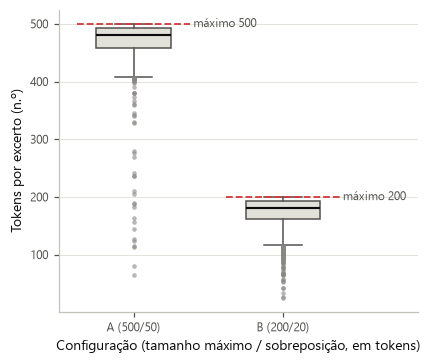

In [5]:
def estatisticas(t):
    return {"Excertos": len(t), "Média": t.mean(), "Mediana": t.median(), "Mínimo": int(t.min()),
            "1.º quartil": t.quantile(0.25), "3.º quartil": t.quantile(0.75), "Máximo": int(t.max())}


t1b = pd.DataFrame({f"{c} (máximo {m})": estatisticas(excertos[c]["tokens"]) for c, m in [("A", 500), ("B", 200)]}).T
t1b = t1b.astype({"Excertos": int, "Mínimo": int, "Máximo": int})
display(tabela(t1b, casas=1, legenda="Tokens por excerto"))

fig, ax = plt.subplots(figsize=(LARGURA * 0.6, 3.2), layout="constrained")
ax.boxplot([excertos["A"]["tokens"], excertos["B"]["tokens"]], tick_labels=["A (500/50)", "B (200/20)"], widths=0.5,
           patch_artist=True, boxprops={"facecolor": "#e1e0d9", "edgecolor": "#52514e"},
           medianprops={"color": "#0b0b0b", "linewidth": 1.4}, whiskerprops={"color": "#52514e"},
           capprops={"color": "#52514e"}, flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#898781",
                                                       "markeredgecolor": "none", "alpha": 0.6})
for pos, maximo in [(1, 500), (2, 200)]:
    ax.hlines(maximo, pos - 0.38, pos + 0.38, colors="#d03b3b", linestyles="--", linewidth=1.2)
    ax.text(pos + 0.4, maximo, f"máximo {maximo}", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0.5, 2.9)
ax.set_ylabel("Tokens por excerto (n.º)")
ax.set_xlabel("Configuração (tamanho máximo / sobreposição, em tokens)")
virgula(ax, casas=0)
regista(fig, "1_tokens_por_excerto")
plt.show()

**O que mostra:** a distribuição dos tokens por excerto na A e na B (caixa entre o 1.º e o 3.º quartil, traço na mediana), com o máximo de cada configuração a tracejado.

## 2. Embeddings no E1

Os 7 embeddings nas configurações A, B e C, com as 12 perguntas que têm resposta (8 factual e 4 multi_doc).

- A e B: pesquisa densa (`experiments/E1/modelos/embeddings/`). C: excertos A e pesquisa híbrida, densa + BM25 com RRF (`experiments/E1/modelos/hibrida/`).
- Regra do E1: o excerto acerta se cobrir pelo menos 50% do mais curto (excerto ou trecho); Recall@5 e MRR@5.

In [6]:
def pasta_emb(m, c):
    return EXP / "modelos" / ("hibrida" if c == "C" else "embeddings") / f"{m}_{'A' if c == 'C' else c}"


linhas, versoes = [], set()
for m in MODELOS_EMB:
    for c in CONFIGS:
        cfg = le_json(pasta_emb(m, c) / "config.json")
        me, e2 = cfg["metrics"], cfg["metrics_e2"]
        if "embedding" in cfg:
            versoes.add((cfg["date"], cfg["embedding"]["ollama_version"]))
        linhas.append({"modelo": m, "config": c, "recall5": me["recall_at_5"], "mrr5": me["mrr_at_5"],
                       "recall5_factual": me["recall_at_5_factual"], "mrr5_factual": me["mrr_at_5_factual"],
                       "recall5_multi_doc": me["recall_at_5_multi_doc"], "mrr5_multi_doc": me["mrr_at_5_multi_doc"],
                       "cobertura_multi_doc": me["cobertura_total_multi_doc"],
                       "recall5_e2": e2["recall_at_5"], "mrr10_e2": e2["mrr_at_10"]})
emb = pd.DataFrame(linhas)
print("Corridas (data, versão do Ollama):", sorted(versoes))


def por_modelo(colunas, nomes):
    t = emb.pivot(index="modelo", columns="config", values=colunas).reindex(MODELOS_EMB)
    t.index = [NOME_EMB[m] for m in t.index]
    t.columns = pd.MultiIndex.from_tuples([(nomes[a], b) for a, b in t.columns])
    return t


t2a = por_modelo(["recall5", "mrr5"], {"recall5": "Recall@5", "mrr5": "MRR@5"})
tabela(t2a, legenda="Recall@5 e MRR@5 por embedding e configuração (12 perguntas, regra do E1)")

Corridas (data, versão do Ollama): [('2026-11-08', '0.40.15')]


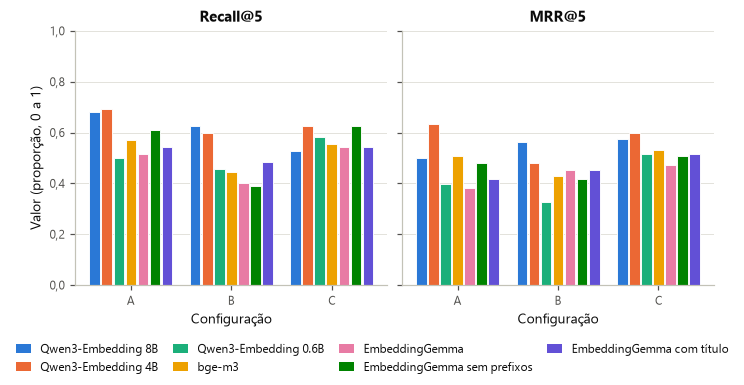

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(LARGURA, 3.4), sharey=True, layout="constrained")
for ax, (col, rotulo) in zip(eixos, [("recall5", "Recall@5"), ("mrr5", "MRR@5")]):
    v = emb.set_index(["modelo", "config"])[col]
    barras(ax, CONFIGS, MODELOS_EMB, lambda s, g: v[(s, g)], COR_EMB, NOME_EMB)
    ax.set_title(rotulo)
    ax.set_xlabel("Configuração")
    ax.set_ylim(0, 1)
    virgula(ax, casas=1)
eixos[0].set_ylabel("Valor (proporção, 0 a 1)")
legenda_modelos(fig, MODELOS_EMB, COR_EMB, NOME_EMB)
regista(fig, "2_recall_mrr_por_embedding")
plt.show()

**O que mostra:** o Recall@5 e o MRR@5 de cada embedding na A, na B e na C, nas 12 perguntas com resposta.

In [8]:
cols = ["recall5_factual", "mrr5_factual", "recall5_multi_doc", "mrr5_multi_doc"]
t2b = emb.pivot(index="modelo", columns="config", values=cols).reindex(MODELOS_EMB)
t2b.index = [NOME_EMB[m] for m in t2b.index]
rot = {"recall5_factual": ("factual (8)", "Recall@5"), "mrr5_factual": ("factual (8)", "MRR@5"),
       "recall5_multi_doc": ("multi_doc (4)", "Recall@5"), "mrr5_multi_doc": ("multi_doc (4)", "MRR@5")}
t2b.columns = pd.MultiIndex.from_tuples([(*rot[a], b) for a, b in t2b.columns])
tabela(t2b, legenda="Recall@5 e MRR@5 por tipo de pergunta (regra do E1)")

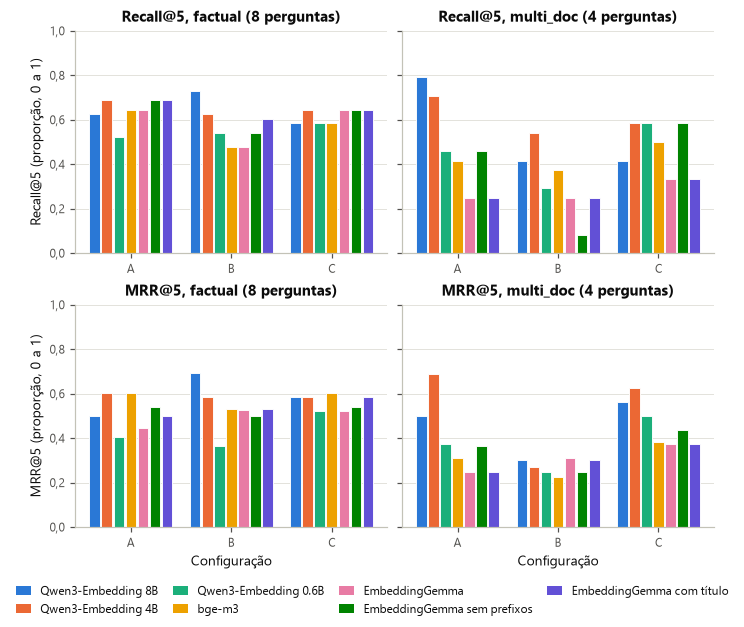

In [9]:
fig, eixos = plt.subplots(2, 2, figsize=(LARGURA, 5.6), sharey=True, layout="constrained")
for i, (met, rotulo) in enumerate([("recall5", "Recall@5"), ("mrr5", "MRR@5")]):
    for j, (tipo, n) in enumerate([("factual", 8), ("multi_doc", 4)]):
        ax = eixos[i, j]
        v = emb.set_index(["modelo", "config"])[f"{met}_{tipo}"]
        barras(ax, CONFIGS, MODELOS_EMB, lambda s, g: v[(s, g)], COR_EMB, NOME_EMB)
        ax.set_title(f"{rotulo}, {tipo} ({n} perguntas)")
        ax.set_ylim(0, 1)
        virgula(ax, casas=1)
        if i == 1:
            ax.set_xlabel("Configuração")
    eixos[i, 0].set_ylabel(f"{rotulo} (proporção, 0 a 1)")
legenda_modelos(fig, MODELOS_EMB, COR_EMB, NOME_EMB)
regista(fig, "2_recall_mrr_por_tipo")
plt.show()

**O que mostra:** o Recall@5 e o MRR@5 de cada embedding, separados pelas 8 perguntas factual e pelas 4 multi_doc.

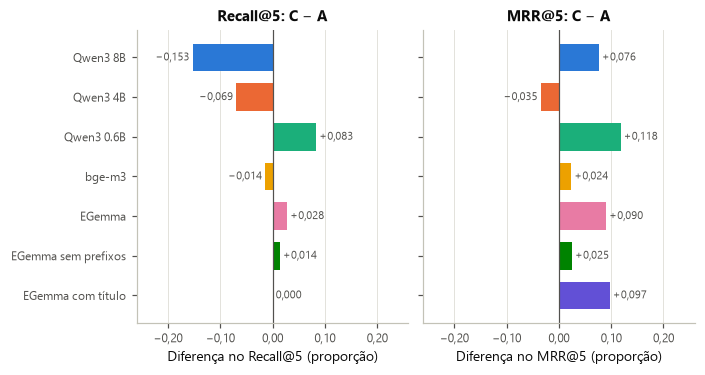

In [10]:
v = emb.set_index(["modelo", "config"])
t2c = pd.DataFrame({(rotulo, k): [v.loc[(m, "A"), col] if k == "A" else v.loc[(m, "C"), col] if k == "C"
                                  else v.loc[(m, "C"), col] - v.loc[(m, "A"), col] for m in MODELOS_EMB]
                    for col, rotulo in [("recall5", "Recall@5"), ("mrr5", "MRR@5")] for k in ["A", "C", "C − A"]},
                   index=[NOME_EMB[m] for m in MODELOS_EMB])
display(tabela(t2c, legenda="Diferença da C (híbrida) em relação à A (densa), com os mesmos excertos"))

fig, eixos = plt.subplots(1, 2, figsize=(LARGURA, 3.3), sharey=True, layout="constrained")
y = np.arange(len(MODELOS_EMB))[::-1]
for ax, rotulo in zip(eixos, ["Recall@5", "MRR@5"]):
    d = t2c[(rotulo, "C − A")].to_numpy()
    ax.barh(y, d, color=[COR_EMB[m] for m in MODELOS_EMB], height=0.7)
    ax.axvline(0, color="#52514e", linewidth=0.8)
    for yi, di in zip(y, d):
        ax.text(di + (0.006 if di >= 0 else -0.006), yi, num(di, 3, sinal=abs(di) >= 5e-4), va="center",
                ha="left" if di >= 0 else "right", fontsize=7.5, color="#52514e")
    ax.set_yticks(y, [CURTO_EMB[m].replace("\n", " ") for m in MODELOS_EMB])
    ax.set_title(f"{rotulo}: C − A")
    ax.set_xlabel(f"Diferença no {rotulo} (proporção)")
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
    lim = max(abs(t2c[(r, "C − A")]).max() for r in ["Recall@5", "MRR@5"]) * 1.7
    ax.set_xlim(-lim, lim)
    virgula(ax, "x", casas=2)
regista(fig, "2_diferenca_C_menos_A")
plt.show()

**O que mostra:** quanto o Recall@5 e o MRR@5 de cada embedding mudam da A (pesquisa densa) para a C (híbrida), com os mesmos excertos de 500 tokens; à direita do zero, a C tem o valor maior.

In [11]:
t2d = emb.assign(modelo=emb["modelo"].map(NOME_EMB)).set_index(["modelo", "config"])[
    ["recall5", "recall5_e2", "mrr5", "mrr10_e2"]]
t2d.columns = pd.MultiIndex.from_tuples([("Recall@5", "E1 (≥ 50%)"), ("Recall@5", "E2 (≥ 1 carácter)"),
                                         ("MRR", "E1: MRR@5"), ("MRR", "E2: MRR@10")])
t2d.index.names = ["Embedding", "Config."]
tabela(t2d, legenda="As duas regras de acerto lado a lado")

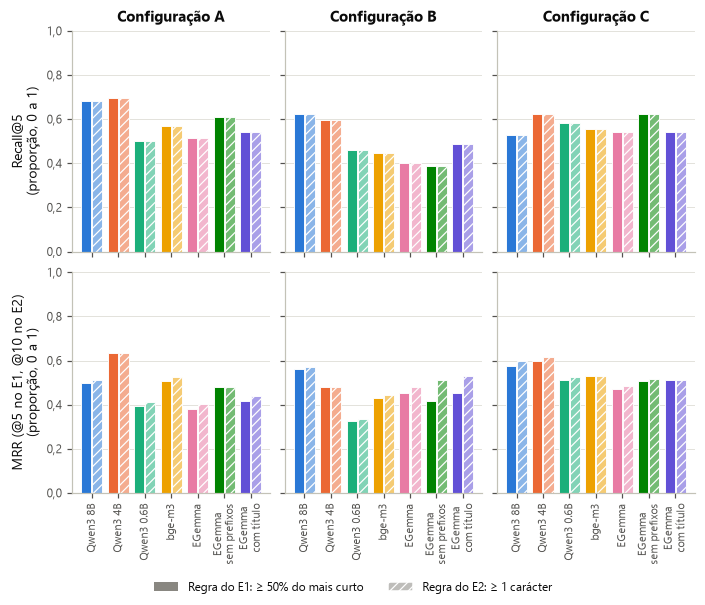

In [12]:
fig, eixos = plt.subplots(2, 3, figsize=(LARGURA, 5.4), sharey=True, layout="constrained")
x = np.arange(len(MODELOS_EMB))
for i, (e1, e2, rotulo) in enumerate([("recall5", "recall5_e2", "Recall@5"), ("mrr5", "mrr10_e2", "MRR (@5 no E1, @10 no E2)")]):
    for j, c in enumerate(CONFIGS):
        ax = eixos[i, j]
        d = emb[emb["config"] == c].set_index("modelo").reindex(MODELOS_EMB)
        cores = [COR_EMB[m] for m in MODELOS_EMB]
        ax.bar(x - 0.21, d[e1], width=0.38, color=cores, edgecolor="white", linewidth=0.6)
        ax.bar(x + 0.21, d[e2], width=0.38, color=[mistura(k) for k in cores], edgecolor="white", linewidth=0.6, hatch="////")
        ax.set_xticks(x, [CURTO_EMB[m] for m in MODELOS_EMB] if i == 1 else [], rotation=90, fontsize=7)
        ax.grid(axis="x", visible=False)
        ax.set_ylim(0, 1)
        virgula(ax, casas=1)
        if i == 0:
            ax.set_title(f"Configuração {c}")
    eixos[i, 0].set_ylabel(f"{rotulo}\n(proporção, 0 a 1)")
fig.legend(handles=[Patch(facecolor="#898781", label="Regra do E1: ≥ 50% do mais curto"),
                    Patch(facecolor=mistura("#898781"), hatch="////", edgecolor="white", label="Regra do E2: ≥ 1 carácter")],
           loc="outside lower center", ncol=2)
regista(fig, "2_regras_E1_E2")
plt.show()

**O que mostra:** para cada embedding e configuração, o Recall@5 e o MRR pelas duas regras de acerto (barra cheia: regra do E1; barra mais clara e riscada: regra do E2).

In [13]:
def primeiro_acerto(recuperados, evidencias, ate=10):
    # Posição do primeiro excerto que acerta num trecho (regra do E1), entre os 10 que ficaram registados.
    for r, c in enumerate(recuperados[:ate], start=1):
        if any(metricas.acerta(c, e) for e in evidencias):
            return r
    return None


COM_RESPOSTA = [q for q, d in PERGUNTAS.items() if d["evidence"]]
pos = {}
for m in MODELOS_EMB:
    for c in CONFIGS:
        for x in comum.le_jsonl(pasta_emb(m, c) / "results.jsonl"):
            ev = PERGUNTAS[x["question_id"]]["evidence"]
            if not ev:
                continue
            p = primeiro_acerto(x["retrieved"], ev)
            # Confere com o hit_ranks gravado (que só vai até ao 5.º na regra do E1).
            assert (p if p and p <= 5 else None) == (x["hit_ranks"][0] if x["hit_ranks"] else None), (m, c, x["question_id"])
            pos[(m, c, x["question_id"])] = p
colunas = [(m, c) for m in MODELOS_EMB for c in CONFIGS]
mapa = pd.DataFrame({k: [pos[(*k, q)] for q in COM_RESPOSTA] for k in colunas}, index=COM_RESPOSTA)


def conta(s):
    return {"1.º": int((s == 1).sum()), "2.º a 5.º": int(s.between(2, 5).sum()), "6.º a 10.º": int(s.between(6, 10).sum()),
            "Fora dos 10": int(s.isna().sum()), "Posição média (das que acertam nos 10)": s.mean()}


t2e = pd.DataFrame({(NOME_EMB[m], c): conta(mapa[(m, c)]) for m, c in colunas}).T
t2e = t2e.astype({k: int for k in ["1.º", "2.º a 5.º", "6.º a 10.º", "Fora dos 10"]})
t2e.index.names = ["Embedding", "Config."]
tabela(t2e, casas=1, legenda="Posição do primeiro acerto (n.º de perguntas, em 12)")

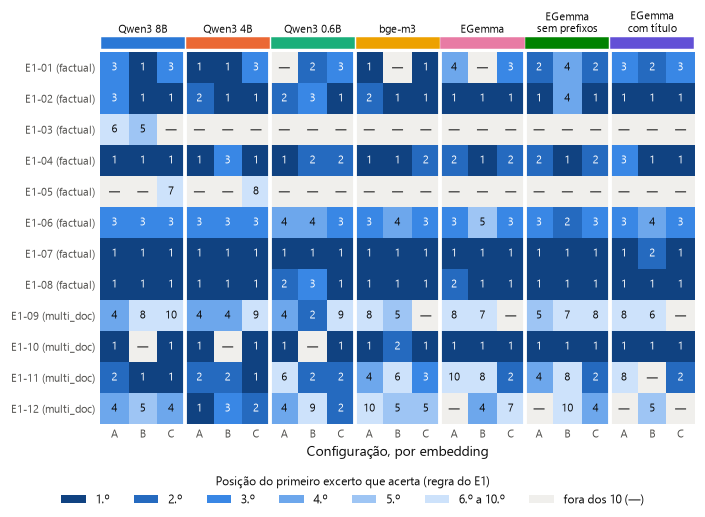

In [14]:
classes = [1, 2, 3, 4, 5, 6]  # 6 = do 6.º ao 10.º; 0 = fora dos 10
cores_pos = {0: NEUTRO, 1: "#104281", 2: "#256abf", 3: "#3987e5", 4: "#6da7ec", 5: "#9ec5f4", 6: AZUL[100]}
codigo = mapa.apply(lambda s: s.map(lambda p: 0 if pd.isna(p) else min(int(p), 6)))
cmap = ListedColormap([cores_pos[k] for k in range(7)])

fig, ax = plt.subplots(figsize=(LARGURA, 4.6), layout="constrained")
ax.imshow(codigo.to_numpy(), cmap=cmap, vmin=-0.5, vmax=6.5, aspect="auto")
for i, q in enumerate(COM_RESPOSTA):
    for j, k in enumerate(colunas):
        p = mapa.loc[q, k]
        ax.text(j, i, "—" if pd.isna(p) else str(int(p)), ha="center", va="center", fontsize=7,
                color="white" if not pd.isna(p) and p <= 3 else "#0b0b0b")
ax.set_xticks(range(len(colunas)), [c for _, c in colunas], fontsize=7)
ax.set_yticks(range(len(COM_RESPOSTA)), [f"{q} ({TIPOS[PERGUNTAS[q]['type']]})" for q in COM_RESPOSTA], fontsize=7.5)
ax.tick_params(length=0)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for b in range(1, len(MODELOS_EMB)):
    ax.axvline(b * 3 - 0.5, color="white", linewidth=2.5)
for b, m in enumerate(MODELOS_EMB):  # nome e cor do modelo por cima de cada bloco de 3 colunas
    ax.add_patch(plt.Rectangle((b * 3 - 0.45, -0.95), 2.9, 0.33, color=COR_EMB[m], clip_on=False))
    ax.text(b * 3 + 1, -1.05, CURTO_EMB[m], ha="center", va="bottom", fontsize=7, clip_on=False)
ax.set_ylim(len(COM_RESPOSTA) - 0.5, -0.5)
ax.set_xlabel("Configuração, por embedding")
fig.legend(handles=[Patch(facecolor=cores_pos[k], label=r) for k, r in
                    [(1, "1.º"), (2, "2.º"), (3, "3.º"), (4, "4.º"), (5, "5.º"), (6, "6.º a 10.º"), (0, "fora dos 10 (—)")]],
           loc="outside lower center", ncol=7, title="Posição do primeiro excerto que acerta (regra do E1)",
           title_fontsize=8)
regista(fig, "2_mapa_primeiro_acerto")
plt.show()

**O que mostra:** para cada uma das 12 perguntas com resposta (linhas) e cada embedding e configuração (colunas), a posição do primeiro excerto que acerta num trecho; as posições 6 a 10 são os quase-acertos, e «—» quer dizer que nenhum dos 10 primeiros acerta.

## 3. Escolha do embedding no grupo

Médias por modelo nas 4 áreas: em cada configuração (média de 4 valores) e nas 12 combinações de área e configuração; e o pior caso de cada modelo nas 12.

- E1: Guilherme Lobo Pinto (este relatório); E2: Pedro Gomes; E3: Luís; E4: Pedro Reis.
- E1: os números deste notebook (secção 2), com a regra do E1 (pelo menos 50% do mais curto, MRR@5). No E1, o EmbeddingGemma é a variante com os prefixos do model card, e a C é a híbrida sobre os excertos A.
- E2, E3 e E4: grelha do Pedro (15/11), tal como foi partilhada.
- **O E2 e o E3 usam o critério de 1 carácter de sobreposição e o MRR até ao 10.º excerto (MRR@10), que é a regra do E2. O E1 e o E4 usam o MRR@5.**

In [15]:
GRUPO_CSV = '''area,modelo,config,recall5,mrr
E2,bge-m3,A,0.618,0.625
E2,bge-m3,B,0.688,0.583
E2,bge-m3,C,0.681,0.611
E2,EmbeddingGemma,A,0.736,0.729
E2,EmbeddingGemma,B,0.715,0.729
E2,EmbeddingGemma,C,0.681,0.611
E2,Qwen3-Embedding 4B,A,0.764,0.632
E2,Qwen3-Embedding 4B,B,0.618,0.562
E2,Qwen3-Embedding 4B,C,0.681,0.597
E2,Qwen3-Embedding 8B,A,0.743,0.639
E2,Qwen3-Embedding 8B,B,0.660,0.597
E2,Qwen3-Embedding 8B,C,0.708,0.628
E2,Qwen3-Embedding 0.6B,A,0.465,0.399
E2,Qwen3-Embedding 0.6B,B,0.521,0.542
E2,Qwen3-Embedding 0.6B,C,0.681,0.524
E3,bge-m3,A,0.930,0.840
E3,bge-m3,B,0.630,0.710
E3,bge-m3,C,0.890,0.830
E3,EmbeddingGemma,A,0.880,0.780
E3,EmbeddingGemma,B,0.790,0.670
E3,EmbeddingGemma,C,0.830,0.770
E3,Qwen3-Embedding 4B,A,0.830,0.890
E3,Qwen3-Embedding 4B,B,0.790,0.780
E3,Qwen3-Embedding 4B,C,0.880,0.810
E3,Qwen3-Embedding 8B,A,0.890,0.890
E3,Qwen3-Embedding 8B,B,0.860,0.730
E3,Qwen3-Embedding 8B,C,0.930,0.790
E3,Qwen3-Embedding 0.6B,A,0.830,0.750
E3,Qwen3-Embedding 0.6B,B,0.830,0.680
E3,Qwen3-Embedding 0.6B,C,0.960,0.850
E4,bge-m3,A,0.625,0.711
E4,bge-m3,B,0.708,0.632
E4,bge-m3,C,0.792,0.715
E4,EmbeddingGemma,A,0.542,0.451
E4,EmbeddingGemma,B,0.583,0.486
E4,EmbeddingGemma,C,0.750,0.531
E4,Qwen3-Embedding 4B,A,0.750,0.649
E4,Qwen3-Embedding 4B,B,0.625,0.521
E4,Qwen3-Embedding 4B,C,0.625,0.611
E4,Qwen3-Embedding 8B,A,0.708,0.556
E4,Qwen3-Embedding 8B,B,0.667,0.433
E4,Qwen3-Embedding 8B,C,0.583,0.574
E4,Qwen3-Embedding 0.6B,A,0.417,0.433
E4,Qwen3-Embedding 0.6B,B,0.458,0.392
E4,Qwen3-Embedding 0.6B,C,0.500,0.528
'''
AREAS = {"E1": "E1 (Guilherme Lobo Pinto)", "E2": "E2 (Pedro Gomes)", "E3": "E3 (Luís)", "E4": "E4 (Pedro Reis)"}
DO_E1 = {"qwen3-embedding-8b": "Qwen3-Embedding 8B", "qwen3-embedding-4b": "Qwen3-Embedding 4B",
         "qwen3-embedding-0.6b": "Qwen3-Embedding 0.6B", "bge-m3": "bge-m3", "embeddinggemma": "EmbeddingGemma"}
e1 = (emb[emb["modelo"].isin(DO_E1)].assign(area="E1", modelo=lambda d: d["modelo"].map(DO_E1))
      .rename(columns={"mrr5": "mrr"})[["area", "modelo", "config", "recall5", "mrr"]])
grupo = pd.concat([e1, pd.read_csv(io.StringIO(GRUPO_CSV))], ignore_index=True)
assert (grupo.groupby("modelo").size() == 12).all(), "Cada modelo tem de ter 4 áreas × 3 configurações"


def pior(d, col):
    m = d[col].min()
    onde = ", ".join(f"{a} {c}" for a, c in d.loc[d[col] == m, ["area", "config"]].itertuples(index=False))
    return m, onde


t3 = {}
for modelo in DO_E1.values():
    d = grupo[grupo["modelo"] == modelo]
    linha = {}
    for col, rot in [("recall5", "Recall@5"), ("mrr", "MRR")]:
        for c in CONFIGS:
            linha[(rot, f"Média {c}")] = d.loc[d["config"] == c, col].mean()
        linha[(rot, "Média nas 12")] = d[col].mean()
        linha[(rot, "Pior caso")], linha[(rot, "Onde")] = pior(d, col)
    t3[modelo] = linha
t3 = pd.DataFrame(t3).T
t3.columns = pd.MultiIndex.from_tuples(t3.columns)
t3.index.name = "Embedding"
display(tabela(t3, legenda="Média por modelo nas 4 áreas (por configuração e nas 12 combinações) e pior caso"))
display(Markdown("Áreas: " + "; ".join(AREAS.values()) + ". O E2 e o E3 contam o acerto com 1 carácter e o MRR até ao 10.º; "
                 "o E1 usa a regra do E1 (≥ 50% do mais curto, MRR@5), e o E4 o MRR@5."))

Áreas: E1 (Guilherme Lobo Pinto); E2 (Pedro Gomes); E3 (Luís); E4 (Pedro Reis). O E2 e o E3 contam o acerto com 1 carácter e o MRR até ao 10.º; o E1 usa a regra do E1 (≥ 50% do mais curto, MRR@5), e o E4 o MRR@5.

## 4. LLM no E1

Os 4 LLM nas configurações A, B e C (15 perguntas cada), com os excertos do Qwen3-Embedding 8B, avaliados pelos dois juízes (`experiments/E1/modelos/llm`, `llm_B` e `llm_C`).

As médias usam as mesmas definições do `rag/avalia_juiz.py`:
- correção (0 a 2): média nas 12 perguntas com resposta; também em pontos, de 24;
- fidelidade (0 a 1) e citações (0 a 2): média nas respostas que não se abstêm; afirmações sem suporte: total nessas respostas;
- abstenções certas: nas 3 perguntas sem resposta; indevidas: nas 12 com resposta (pela frase de abstenção, detetada em código);
- segundos por resposta: média das 15.

Onde o juiz ainda não avaliou as 15 respostas, as médias usam só as avaliadas: a coluna «Avaliadas» diz quantas, e nas figuras essas barras levam riscas.

In [16]:
PASTA_LLM = {"A": EXP / "modelos" / "llm", "B": EXP / "modelos" / "llm_B", "C": EXP / "modelos" / "llm_C"}


def valor(a, k):
    return np.nan if a is None or a.get(k) is None else float(a[k])


linhas = []
for c, pasta in PASTA_LLM.items():
    for m in LLMS:
        respostas = comum.le_jsonl(pasta / m / "results.jsonl")
        for j in JUIZES:
            f = pasta / m / f"juiz_{j}.jsonl"
            aval = {a["question_id"]: a["judge"] for a in comum.le_jsonl(f)} if f.exists() else {}
            for x in respostas:
                a = aval.get(x["question_id"])
                linhas.append({"config": c, "modelo": m, "juiz": j, "pergunta": x["question_id"], "tipo": x["type"],
                               "abstencao": bool(x["abstained"]), "segundos": x["latency_s"], "avaliada": a is not None,
                               **{k: valor(a, k) for k in ["correcao", "fidelidade", "nao_suportadas", "citacoes"]}})
llm = pd.DataFrame(linhas)


def grelha(d):
    com, sem, resp = d[d["tipo"] != "unanswerable"], d[d["tipo"] == "unanswerable"], d[~d["abstencao"]]
    fr = lambda a, n: f"{a}/{n}" if n else "—"
    return pd.Series({"Correção (0 a 2)": com["correcao"].mean(), "Correção (pontos)": com["correcao"].sum(min_count=1),
                      "Fidelidade (0 a 1)": resp["fidelidade"].mean(),
                      "Afirmações sem suporte (n.º)": resp["nao_suportadas"].sum(min_count=1),
                      "Citações (0 a 2)": resp["citacoes"].mean(),
                      "Abstenções certas": fr(int(sem["abstencao"].sum()), len(sem)),
                      "Abstenções indevidas": fr(int(com["abstencao"].sum()), len(com)),
                      "Segundos por resposta (s)": d["segundos"].mean(),
                      "Avaliadas": f"{int(d['avaliada'].sum())}/{len(d)}"})


def provisorio(d):
    return d.groupby(["juiz", "config", "modelo"])["avaliada"].all()


COMPLETO = provisorio(llm)
falta = COMPLETO[~COMPLETO]
print("Por avaliar por completo:", ", ".join(f"{j} {c} {NOME_LLM[m]}" for j, c, m in falta.index) or "nada")

t4a = llm.groupby(["juiz", "config", "modelo"], sort=False).apply(grelha, include_groups=False)
t4a = t4a.rename(index=NOME_LLM, level="modelo")
t4a.index.names = ["Juiz", "Config.", "LLM"]
tabela(t4a, por_coluna={"Correção (pontos)": 0, "Afirmações sem suporte (n.º)": 0, "Segundos por resposta (s)": 1},
       legenda="Grelha do juiz por LLM e configuração")

Por avaliar por completo: nada


,,,Correção (0 a 2),Correção (pontos),Fidelidade (0 a 1),Afirmações sem suporte (n.º),Citações (0 a 2),Abstenções certas,Abstenções indevidas,Segundos por resposta (s),Avaliadas
Juiz,Config.,LLM,,,,,,,,,
gpt-oss-120b,A,Gemma 4 12B,"1,500",18,"0,958",1,"1,833",2/3,1/12,"3,2",15/15
gpt-oss-20b,A,Gemma 4 12B,"1,500",18,"0,931",2,"1,833",2/3,1/12,"3,2",15/15
gpt-oss-120b,A,Qwen3.5 9B,"1,417",17,"0,874",9,"1,667",3/3,0/12,"2,9",15/15
gpt-oss-20b,A,Qwen3.5 9B,"1,250",15,"0,924",5,"1,750",3/3,0/12,"2,9",15/15
gpt-oss-120b,A,AMALIA 9B,"1,333",16,"0,782",11,"1,071",1/3,0/12,"2,7",15/15
gpt-oss-20b,A,AMALIA 9B,"1,417",17,"0,809",6,"1,214",1/3,0/12,"2,7",15/15
gpt-oss-120b,A,Ministral 3 14B,"1,333",16,"0,900",4,"1,500",3/3,2/12,"4,3",15/15
gpt-oss-20b,A,Ministral 3 14B,"1,583",19,"0,893",5,"1,700",3/3,2/12,"4,3",15/15
gpt-oss-120b,B,Gemma 4 12B,"1,167",14,"0,876",5,"1,545",2/3,2/12,"2,4",15/15


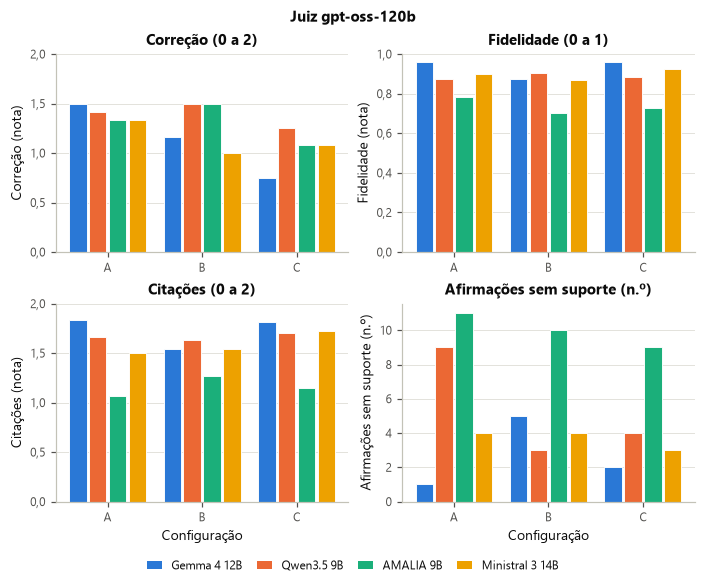

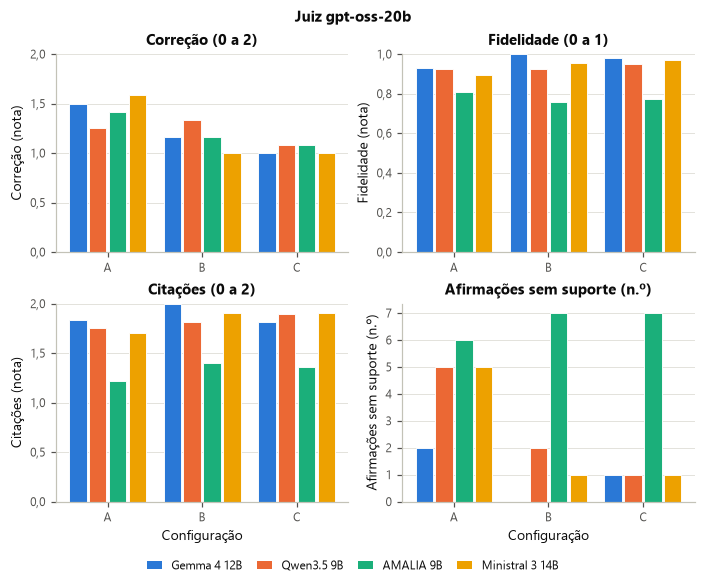

In [17]:
def media_llm(d, col, como="mean"):
    g = d.groupby(["modelo", "config"])[col]
    return getattr(g, como)() if como != "sum" else g.sum(min_count=1)


def notas_avaliacao(d):
    # Para grupos que o juiz ainda não avaliou por completo (d: as linhas de um juiz):
    # a entrada «provisório» da legenda e uma nota para o título com os que ainda não têm nenhuma avaliação.
    av = d.groupby(["config", "modelo"])["avaliada"].agg(["sum", "size"])
    parcial, nada = av[(av["sum"] > 0) & (av["sum"] < av["size"])], av[av["sum"] == 0]
    extra = [Patch(facecolor="#898781", hatch="////", edgecolor="white", label="provisório (faltam avaliações)")] if len(parcial) else []
    nota = ("; sem barra, por avaliar: " + ", ".join(f"{c} {NOME_LLM[m]}" for c, m in nada.index)) if len(nada) else ""
    return extra, nota


for j in JUIZES:
    d = llm[llm["juiz"] == j]
    com, resp = d[d["tipo"] != "unanswerable"], d[~d["abstencao"]]
    paineis = [("Correção (0 a 2)", media_llm(com, "correcao"), (0, 2)),
               ("Fidelidade (0 a 1)", media_llm(resp, "fidelidade"), (0, 1)),
               ("Citações (0 a 2)", media_llm(resp, "citacoes"), (0, 2)),
               ("Afirmações sem suporte (n.º)", media_llm(resp, "nao_suportadas", "sum"), None)]
    fig, eixos = plt.subplots(2, 2, figsize=(LARGURA, 5.2), layout="constrained")
    for ax, (rotulo, v, lim) in zip(eixos.flat, paineis):
        barras(ax, CONFIGS, LLMS, lambda s, g: v.get((s, g), np.nan), COR_LLM, NOME_LLM,
               tracejado=lambda s, g: not COMPLETO[(j, g, s)])
        ax.set_title(rotulo)
        ax.set_ylabel(rotulo.split(" (")[0] + (" (nota)" if "0 a" in rotulo else " (n.º)"))
        escala(ax, lim, inteiros=lim is None)
    for ax in eixos[1]:
        ax.set_xlabel("Configuração")
    extra, nota = notas_avaliacao(d)
    legenda_modelos(fig, LLMS, COR_LLM, NOME_LLM, ncol=len(LLMS) + len(extra), extra=extra)
    fig.suptitle(f"Juiz {j}{nota}", fontsize=9.5, fontweight="bold")
    regista(fig, f"4_grelha_{j}")
    plt.show()

**O que mostram:** uma figura por juiz, com a correção, a fidelidade, as citações e as afirmações sem suporte de cada LLM na A, na B e na C; as barras com riscas são de grupos que o juiz ainda não avaliou por completo.

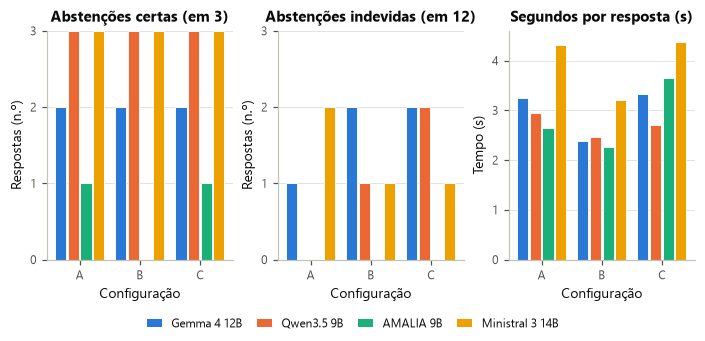

In [18]:
d = llm[llm["juiz"] == JUIZES[0]]  # as abstenções e os segundos não dependem do juiz
com, sem = d[d["tipo"] != "unanswerable"], d[d["tipo"] == "unanswerable"]
paineis = [("Abstenções certas (em 3)", media_llm(sem, "abstencao", "sum"), (0, 3)),
           ("Abstenções indevidas (em 12)", media_llm(com, "abstencao", "sum"), (0, 3)),
           ("Segundos por resposta (s)", media_llm(d, "segundos"), None)]
fig, eixos = plt.subplots(1, 3, figsize=(LARGURA, 3.0), layout="constrained")
for ax, (rotulo, v, lim) in zip(eixos, paineis):
    barras(ax, CONFIGS, LLMS, lambda s, g: float(v.get((s, g), np.nan)), COR_LLM, NOME_LLM)
    ax.set_title(rotulo)
    ax.set_xlabel("Configuração")
    ax.set_ylabel("Respostas (n.º)" if lim else "Tempo (s)")
    if lim:
        ax.set_ylim(*lim)
        ax.set_yticks(range(lim[1] + 1))
    else:
        virgula(ax, casas=0)
legenda_modelos(fig, LLMS, COR_LLM, NOME_LLM)
regista(fig, "4_abstencoes_segundos")
plt.show()

**O que mostra:** as abstenções certas (nas 3 perguntas sem resposta), as indevidas (nas 12 com resposta) e os segundos por resposta de cada LLM na A, na B e na C; não dependem do juiz.

In [19]:
def grelha_tipo(d):
    resp = d[~d["abstencao"]]
    return pd.Series({"Correção (0 a 2)": d["correcao"].mean(), "Fidelidade (0 a 1)": resp["fidelidade"].mean(),
                      "Afirmações sem suporte (n.º)": resp["nao_suportadas"].sum(min_count=1),
                      "Citações (0 a 2)": resp["citacoes"].mean(), "Abstenções": f"{int(d['abstencao'].sum())}/{len(d)}",
                      "Segundos por resposta (s)": d["segundos"].mean(), "Avaliadas": f"{int(d['avaliada'].sum())}/{len(d)}"})


t4b = llm.assign(tipo=llm["tipo"].map(TIPOS)).groupby(["juiz", "tipo", "config", "modelo"], sort=False).apply(
    grelha_tipo, include_groups=False).rename(index=NOME_LLM, level="modelo")
t4b.index.names = ["Juiz", "Tipo", "Config.", "LLM"]
tabela(t4b, por_coluna={"Afirmações sem suporte (n.º)": 0, "Segundos por resposta (s)": 1},
       legenda="Grelha por tipo de pergunta (8 factual, 4 multi_doc, 3 sem resposta)")

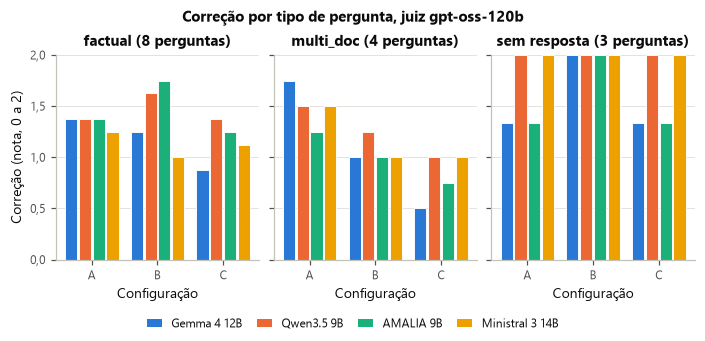

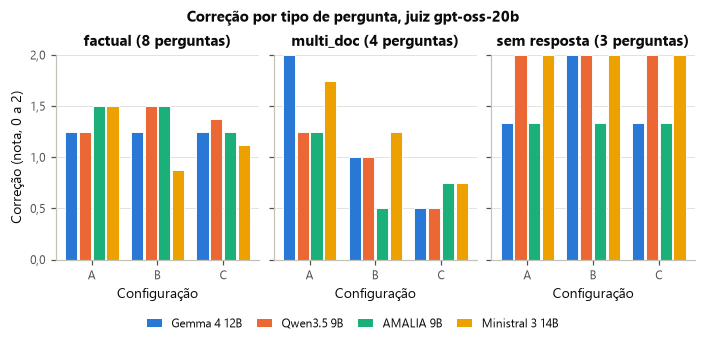

In [20]:
for j in JUIZES:
    d = llm[llm["juiz"] == j]
    fig, eixos = plt.subplots(1, 3, figsize=(LARGURA, 3.0), sharey=True, layout="constrained")
    for ax, (tipo, n) in zip(eixos, [("factual", 8), ("multi_doc", 4), ("unanswerable", 3)]):
        v = media_llm(d[d["tipo"] == tipo], "correcao")
        sub = d[d["tipo"] == tipo].groupby(["config", "modelo"])["avaliada"].all()
        barras(ax, CONFIGS, LLMS, lambda s, g: v.get((s, g), np.nan), COR_LLM, NOME_LLM,
               tracejado=lambda s, g: not sub[(g, s)])
        ax.set_title(f"{TIPOS[tipo]} ({n} perguntas)")
        ax.set_xlabel("Configuração")
        escala(ax, (0, 2))
    eixos[0].set_ylabel("Correção (nota, 0 a 2)")
    extra, nota = notas_avaliacao(d)
    legenda_modelos(fig, LLMS, COR_LLM, NOME_LLM, ncol=len(LLMS) + len(extra), extra=extra)
    fig.suptitle(f"Correção por tipo de pergunta, juiz {j}{nota}", fontsize=9.5, fontweight="bold")
    regista(fig, f"4_correcao_por_tipo_{j}")
    plt.show()

**O que mostram:** a correção média de cada LLM em cada configuração, separada pelos três tipos de pergunta, uma figura por juiz.

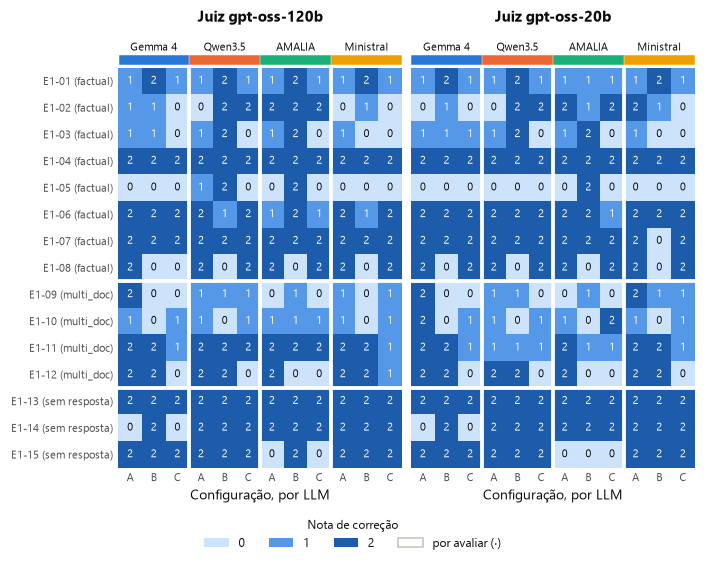

In [21]:
cores_nota = ListedColormap([AZUL[100], AZUL[350], AZUL[550]])
colunas_llm = [(m, c) for m in LLMS for c in CONFIGS]
perguntas = list(PERGUNTAS)
t4c = {}
fig, eixos = plt.subplots(1, 2, figsize=(LARGURA, 5.0), sharey=True, layout="constrained")
for ax, j in zip(eixos, JUIZES):
    d = llm[llm["juiz"] == j].set_index(["modelo", "config", "pergunta"])["correcao"]
    M = np.array([[d[(m, c, q)] for (m, c) in colunas_llm] for q in perguntas])
    t4c[j] = pd.DataFrame(M, index=perguntas, columns=pd.MultiIndex.from_tuples([(NOME_LLM[m], c) for m, c in colunas_llm]))
    ax.imshow(np.ma.masked_invalid(M), cmap=cores_nota, vmin=-0.5, vmax=2.5, aspect="auto")
    for i in range(M.shape[0]):
        for k in range(M.shape[1]):
            v = M[i, k]
            ax.text(k, i, "·" if np.isnan(v) else str(int(v)), ha="center", va="center", fontsize=7,
                    color="white" if not np.isnan(v) and v >= 1 else "#0b0b0b")
    ax.set_xticks(range(len(colunas_llm)), [c for _, c in colunas_llm], fontsize=7)
    ax.set_yticks(range(len(perguntas)), [f"{q} ({TIPOS[PERGUNTAS[q]['type']]})" for q in perguntas], fontsize=7.5)
    ax.tick_params(length=0)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for b in range(1, len(LLMS)):
        ax.axvline(b * 3 - 0.5, color="white", linewidth=2.5)
    for b in (8, 12):
        ax.axhline(b - 0.5, color="white", linewidth=2.5)
    for b, m in enumerate(LLMS):
        ax.add_patch(plt.Rectangle((b * 3 - 0.45, -0.95), 2.9, 0.33, color=COR_LLM[m], clip_on=False))
        ax.text(b * 3 + 1, -1.05, CURTO_LLM[m], ha="center", va="bottom", fontsize=7, clip_on=False)
    ax.set_ylim(len(perguntas) - 0.5, -0.5)
    ax.set_title(f"Juiz {j}", pad=30)
    ax.set_xlabel("Configuração, por LLM")
fig.legend(handles=[Patch(facecolor=AZUL[100], label="0"), Patch(facecolor=AZUL[350], label="1"),
                    Patch(facecolor=AZUL[550], label="2"), Patch(facecolor="white", edgecolor="#c3c2b7", label="por avaliar (·)")],
           loc="outside lower center", ncol=4, title="Nota de correção", title_fontsize=8)
regista(fig, "4_mapa_correcao")
display(tabela(pd.concat(t4c, names=["Juiz", "Pergunta"]).T.groupby(level=0, sort=False).mean().T, casas=2,
               legenda="Correção média por pergunta e LLM (média das 3 configurações)"))
plt.show()

**O que mostra:** a nota de correção de cada resposta, com as perguntas nas linhas (factual, multi_doc e sem resposta, separadas por linhas brancas) e as configurações de cada LLM nas colunas, para os dois juízes; «·» é uma resposta que o juiz ainda não avaliou.

## 5. Juízes: gpt-oss-20b contra gpt-oss-120b

Concordância nas respostas do teste dos LLM que os dois juízes já avaliaram, na nota de correção e na de citações (0 a 2). O kappa é o de Cohen, simples e com pesos quadráticos (a mesma conta do `rag/piloto.py`).

In [22]:
from collections import Counter


def kappa(pares, categorias=(0, 1, 2), quadratico=False):
    # Igual ao kappa() do rag/piloto.py.
    if not pares:
        return None
    idx, k = {c: i for i, c in enumerate(categorias)}, len(categorias)
    peso = (lambda i, j: (i - j) ** 2 / (k - 1) ** 2) if quadratico else (lambda i, j: float(i != j))
    n = len(pares)
    observado = sum(peso(idx[a], idx[b]) for a, b in pares) / n
    pa, pb = Counter(a for a, _ in pares), Counter(b for _, b in pares)
    esperado = sum(pa[x] * pb[y] * peso(idx[x], idx[y]) for x in categorias for y in categorias) / n ** 2
    return round(1 - observado / esperado, 3) if esperado else None


lado = llm.set_index(["config", "modelo", "pergunta", "juiz"])[["correcao", "citacoes"]].unstack("juiz")


def pares(criterio, config=None):
    d = lado[criterio].dropna()
    if config:
        d = d[d.index.get_level_values("config") == config]
    return [(int(round(a)), int(round(b))) for a, b in zip(d["gpt-oss-20b"], d["gpt-oss-120b"])]


t5 = {}
for criterio, rot in [("correcao", "Correção"), ("citacoes", "Citações")]:
    for c in CONFIGS + [None]:
        p = pares(criterio, c)
        iguais = sum(a == b for a, b in p)
        t5[(rot, c or "Todas")] = {"Pares": len(p), "Notas iguais": iguais, "Notas iguais (%)": 100 * iguais / len(p),
                                   "Kappa": kappa(p), "Kappa quadrático": kappa(p, quadratico=True)}
t5 = pd.DataFrame(t5).T.astype({"Pares": int, "Notas iguais": int})
t5.index.names = ["Nota", "Config."]
tabela(t5, por_coluna={"Notas iguais (%)": 1}, legenda="Concordância entre os juízes (pares avaliados pelos dois)")

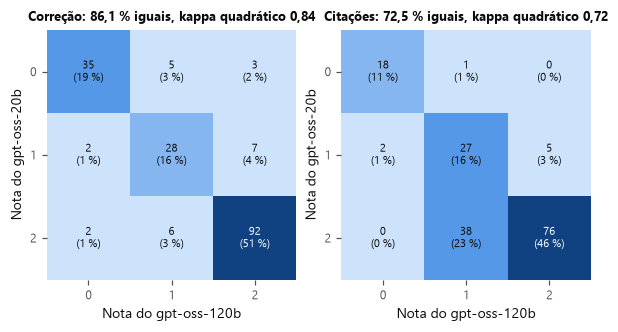

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(LARGURA * 0.85, 3.2), layout="constrained")
for ax, (criterio, rot) in zip(eixos, [("correcao", "Correção"), ("citacoes", "Citações")]):
    p = pares(criterio)
    M = np.zeros((3, 3), dtype=int)
    for a, b in p:
        M[a, b] += 1
    ax.imshow(M, cmap=ListedColormap([AZUL[k] for k in (100, 250, 350, 450, 550, 650)]),
              norm=mpl.colors.BoundaryNorm(np.linspace(0, M.max() + 1, 7), 6))
    for a in range(3):
        for b in range(3):
            ax.text(b, a, f"{M[a, b]}\n({num(100 * M[a, b] / len(p), 0)} %)", ha="center", va="center", fontsize=7.5,
                    color="white" if M[a, b] > M.max() / 2 else "#0b0b0b")
    ax.set_xticks(range(3), ["0", "1", "2"])
    ax.set_yticks(range(3), ["0", "1", "2"])
    ax.set_xlabel("Nota do gpt-oss-120b")
    ax.set_ylabel("Nota do gpt-oss-20b")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    iguais = sum(a == b for a, b in p)
    ax.set_title(f"{rot}: {num(100 * iguais / len(p), 1)} % iguais, kappa quadrático {num(kappa(p, quadratico=True), 2)}",
                 fontsize=8.5)
regista(fig, "5_concordancia_juizes")
plt.show()

**O que mostra:** quantas respostas levam cada par de notas (20b nas linhas, 120b nas colunas), na correção e nas citações; na diagonal estão as notas iguais.

## 6. Experiências finais A, B e C

Recuperação e geração das três experiências (`experiments/E1/A`, `B` e `C`). O embedding, o LLM e o juiz leem-se do `config.json` de cada uma, por isso esta secção acompanha uma troca de modelos (por exemplo, o 8B pelo 4B), desde que as experiências se voltem a correr.

In [24]:
EXPS = ["A", "B", "C"]
cfg_exp = {e: le_json(EXP / e / "config.json") for e in EXPS}
linhas = {}
for e, cfg in cfg_exp.items():
    res = pd.DataFrame(comum.le_jsonl(EXP / e / "results.jsonl"))
    aval = {a["question_id"]: a["judge"] for a in comum.le_jsonl(EXP / e / f"juiz_{cfg['judge']}.jsonl")}
    for k in ["correcao", "fidelidade", "nao_suportadas", "citacoes"]:
        res[k] = [valor(aval.get(q), k) for q in res["question_id"]]
    com, sem, resp = res[res["type"] != "unanswerable"], res[res["type"] == "unanswerable"], res[~res["abstained"]]
    multi = com[com["type"] == "multi_doc"]
    linha = {"Embedding": NOME_EMB.get(cfg["retrieval"]["embedding"], cfg["retrieval"]["embedding"]),
             "Excertos": cfg["run"]["chunks"], "Pesquisa": {"dense": "densa", "hybrid": "híbrida"}[cfg["retrieval"]["mode"]],
             "LLM": NOME_LLM.get(cfg["llm"], cfg["llm"]), "Juiz": cfg["judge"],
             "Recall@5": com["recall_at_5"].mean(), "MRR@5": com["rr"].mean(),
             "Cobertura multi_doc": multi["cobertura_total"].mean(),
             "Correção (0 a 2)": com["correcao"].mean(), "Correção (pontos)": com["correcao"].sum(),
             "Fidelidade (0 a 1)": resp["fidelidade"].mean(), "Afirmações sem suporte (n.º)": resp["nao_suportadas"].sum(),
             "Citações (0 a 2)": resp["citacoes"].mean(),
             "Abstenções certas": f"{int(sem['abstained'].sum())}/{len(sem)}",
             "Abstenções indevidas": f"{int(com['abstained'].sum())}/{len(com)}",
             "Segundos por resposta (s)": res["latency_s"].mean(), "Avaliadas": f"{len(aval)}/{len(res)}"}
    # Confere com as métricas gravadas no config.json.
    gravado = cfg["run"]["retrieval_metrics"]
    assert abs(linha["Recall@5"] - gravado["recall_at_5"]) < 1e-9 and abs(linha["MRR@5"] - gravado["mrr_at_5"]) < 1e-9
    linhas[e] = linha
t6 = pd.DataFrame(linhas).T
t6.index.name = "Experiência"
for col in ["Recall@5", "MRR@5", "Cobertura multi_doc", "Correção (0 a 2)", "Fidelidade (0 a 1)", "Citações (0 a 2)",
            "Segundos por resposta (s)"]:
    t6[col] = t6[col].astype(float)
t6 = t6.astype({"Correção (pontos)": float, "Afirmações sem suporte (n.º)": int})
tabela(t6, por_coluna={"Correção (pontos)": 0, "Segundos por resposta (s)": 1}, legenda="Experiências finais")

,Embedding,Excertos,Pesquisa,LLM,Juiz,Recall@5,MRR@5,Cobertura multi_doc,Correção (0 a 2),Correção (pontos),Fidelidade (0 a 1),Afirmações sem suporte (n.º),Citações (0 a 2),Abstenções certas,Abstenções indevidas,Segundos por resposta (s),Avaliadas
Experiência,,,,,,,,,,,,,,,,,
A,Qwen3-Embedding 8B,A,densa,Gemma 4 12B,gpt-oss-120b,"0,681","0,500","0,500","1,333",16,"0,972",1,"1,917",2/3,1/12,"3,2",15/15
B,Qwen3-Embedding 8B,B,densa,Gemma 4 12B,gpt-oss-120b,"0,625","0,561","0,250","1,167",14,"0,876",5,"1,545",2/3,2/12,"2,4",15/15
C,Qwen3-Embedding 8B,A,híbrida,Gemma 4 12B,gpt-oss-120b,"0,528","0,576","0,250","0,750",9,"0,962",2,"1,818",2/3,2/12,"3,3",15/15


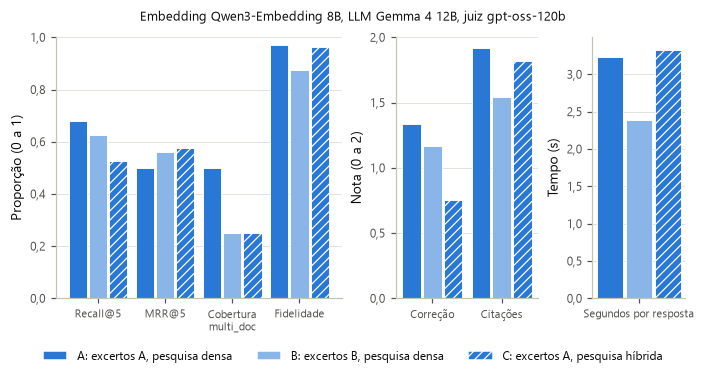

In [25]:
def estilo(e, cor):
    # A: cor cheia; B: mais clara; C: riscas brancas (a cor é a do embedding da experiência).
    return {"A": dict(facecolor=cor), "B": dict(facecolor=mistura(cor)), "C": dict(facecolor=cor, hatch="////")}[e]


paineis = [("Proporção (0 a 1)", ["Recall@5", "MRR@5", "Cobertura multi_doc", "Fidelidade (0 a 1)"], (0, 1)),
           ("Nota (0 a 2)", ["Correção (0 a 2)", "Citações (0 a 2)"], (0, 2)),
           ("Tempo (s)", ["Segundos por resposta (s)"], None)]
fig, eixos = plt.subplots(1, 3, figsize=(LARGURA, 3.3), layout="constrained", width_ratios=[4, 2, 1.3])
for ax, (rotulo, metricas_, lim) in zip(eixos, paineis):
    x = np.arange(len(metricas_))
    for i, e in enumerate(EXPS):
        cor = COR_EMB.get(cfg_exp[e]["retrieval"]["embedding"], "#898781")
        ax.bar(x - 0.3 + 0.3 * i, [t6.loc[e, m] for m in metricas_], width=0.27, edgecolor="white", linewidth=0.6,
               **estilo(e, cor))
    ax.set_xticks(x, [m.split(" (")[0].replace("Cobertura multi_doc", "Cobertura\nmulti_doc") for m in metricas_], fontsize=7.5)
    ax.set_ylabel(rotulo)
    ax.grid(axis="x", visible=False)
    escala(ax, lim)
fig.legend(handles=[Patch(edgecolor="white", label=f"{e}: excertos {cfg_exp[e]['run']['chunks']}, pesquisa {t6.loc[e, 'Pesquisa']}",
                          **estilo(e, COR_EMB.get(cfg_exp[e]["retrieval"]["embedding"], "#898781"))) for e in EXPS],
           loc="outside lower center", ncol=3)
modelos = sorted({(t6.loc[e, "Embedding"], t6.loc[e, "LLM"], t6.loc[e, "Juiz"]) for e in EXPS})
fig.suptitle(" | ".join(f"Embedding {a}, LLM {b}, juiz {c}" for a, b, c in modelos), fontsize=8.5)
regista(fig, "6_experiencias_ABC")
plt.show()

**O que mostra:** as métricas de recuperação (Recall@5, MRR@5, cobertura das multi_doc) e de geração (fidelidade, correção, citações e segundos por resposta) das três experiências, com os modelos de cada uma no título.

## 7. Análise de erros

Número de respostas com cada tipo de falha, nas experiências finais e no teste dos LLM, com o juiz gpt-oss-120b. Uma resposta pode ter mais do que um tipo de falha.

- **Recuperação:** pergunta com resposta (12 por configuração) em que os 5 excertos não têm nenhum trecho certo, ou só têm parte deles (Recall@5 abaixo de 1).
- **Resposta sem suporte:** resposta que não se abstém e tem pelo menos uma afirmação sem suporte nos excertos, segundo o juiz.
- **Citação errada:** resposta que não se abstém e tem nota de citações abaixo de 2 no juiz, ou citações fora dos excertos, mal escritas ou nenhuma (detetadas em código).
- **Abstenção indevida:** pergunta com resposta em que o LLM usa a frase de abstenção (detetada em código), separada pelo que estava nos excertos: com ou sem o trecho certo.

No teste dos LLM, os 4 LLM recebem os mesmos excertos em cada configuração, por isso as falhas de recuperação são iguais para todos. A análise por pergunta está em `experiments/E1/analise_erros.md`.

In [26]:
JUIZ_ERROS = "gpt-oss-120b"
FALHAS = {  # tipo: (respostas que contam, [(detalhe, coluna)])
    "Recuperação": ("com_resposta", [("nenhum trecho certo nos 5 excertos", "rec_nenhum"),
                                     ("só parte dos trechos certos", "rec_parcial")]),
    "Resposta sem suporte": ("responde", [("afirmações sem suporte (juiz)", "sem_suporte")]),
    "Citação errada": ("responde", [("nota de citações abaixo de 2 (juiz)", "cit_juiz"),
                                    ("citações fora dos excertos ou mal escritas (código)", "cit_codigo"),
                                    ("sem citações (código)", "cit_nenhuma")]),
    "Abstenção indevida": ("com_resposta", [("com o trecho certo nos excertos", "abst_com_trecho"),
                                            ("sem o trecho certo nos excertos", "abst_sem_trecho")]),
}


def falhas(pasta, juiz):
    # Uma linha por resposta e uma coluna por falha (verdadeiro ou falso); exige as 15 respostas avaliadas.
    res = comum.le_jsonl(pasta / "results.jsonl")
    aval = {a["question_id"]: a["judge"] for a in comum.le_jsonl(pasta / f"juiz_{juiz}.jsonl")}
    assert len(res) == 15 and set(aval) >= {x["question_id"] for x in res}, f"{pasta}: faltam avaliações do {juiz}"
    linhas = []
    for x in res:
        a, com, responde = aval[x["question_id"]], x["type"] != "unanswerable", not x["abstained"]
        linhas.append({
            "pergunta": x["question_id"], "com_resposta": com, "responde": responde,
            "rec_nenhum": com and x["recall_at_5"] == 0,
            "rec_parcial": com and 0 < x["recall_at_5"] < 1,
            "sem_suporte": responde and (a.get("nao_suportadas") or 0) > 0,
            "cit_juiz": responde and a.get("citacoes") is not None and a["citacoes"] < 2,
            "cit_codigo": responde and bool(x["citations_outside_context"] or x["malformed_citations"]),
            "cit_nenhuma": responde and not x["cited_doc_ids"],
            "abst_com_trecho": com and x["abstained"] and x["recall_at_5"] > 0,
            "abst_sem_trecho": com and x["abstained"] and x["recall_at_5"] == 0,
        })
    d = pd.DataFrame(linhas)
    for tipo, (_, detalhes) in FALHAS.items():
        d[tipo] = d[[c for _, c in detalhes]].any(axis=1)
    return d


EXPERIENCIAS_ = "Experiências finais"
TESTE_ = "Teste dos LLM (A + B + C)"
erros = {(EXPERIENCIAS_, e): falhas(EXP / e, cfg_exp[e]["judge"]) for e in EXPS}
for m in LLMS:
    erros[(TESTE_, NOME_LLM[m])] = pd.concat([falhas(PASTA_LLM[c] / m, JUIZ_ERROS) for c in CONFIGS])

t7 = {}
for col, d in erros.items():
    t7[col] = {}
    for tipo, (base, detalhes) in FALHAS.items():
        conta = lambda c: f"{int(d[c].sum())} de {int(d[base].sum())}"
        t7[col][(tipo, "total")] = conta(tipo)
        if len(detalhes) > 1:
            for rot, c in detalhes:
                t7[col][(tipo, rot)] = conta(c)
t7 = pd.DataFrame(t7)
t7.index.names = ["Falha", "Detalhe"]
juizes_exp = ", ".join(sorted({cfg_exp[e]["judge"] for e in EXPS}))
tabela(t7, legenda=f"Respostas com cada falha («n de N»: N são as respostas que contam para essa falha); "
                   f"juiz {juizes_exp} nas experiências e {JUIZ_ERROS} no teste dos LLM")

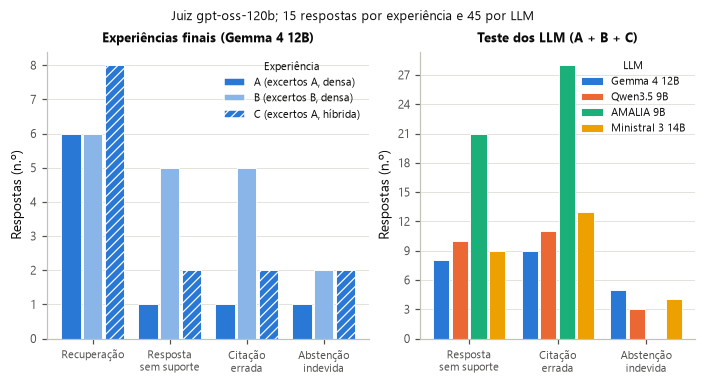

In [27]:
TIPOS_FALHA = list(FALHAS)
CURTO_FALHA = {"Recuperação": "Recuperação", "Resposta sem suporte": "Resposta\nsem suporte",
               "Citação errada": "Citação\nerrada", "Abstenção indevida": "Abstenção\nindevida"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(LARGURA, 3.4), layout="constrained", width_ratios=[4, 3.4])

x = np.arange(len(TIPOS_FALHA))
for i, e in enumerate(EXPS):
    cor = COR_EMB.get(cfg_exp[e]["retrieval"]["embedding"], "#898781")
    ax1.bar(x - 0.28 + 0.28 * i, [erros[(EXPERIENCIAS_, e)][t].sum() for t in TIPOS_FALHA], width=0.25,
            edgecolor="white", linewidth=0.6, **estilo(e, cor))
ax1.set_xticks(x, [CURTO_FALHA[t] for t in TIPOS_FALHA], fontsize=7.5)
ax1.grid(axis="x", visible=False)
ax1.set_ylabel("Respostas (n.º)")
escala(ax1, inteiros=True)
ax1.set_title(f"Experiências finais ({' / '.join(sorted(set(t6['LLM'])))})", fontsize=8.5)
ax1.legend(handles=[Patch(edgecolor="white", label=f"{e} (excertos {cfg_exp[e]['run']['chunks']}, {t6.loc[e, 'Pesquisa']})",
                          **estilo(e, COR_EMB.get(cfg_exp[e]["retrieval"]["embedding"], "#898781"))) for e in EXPS],
           loc="upper right", fontsize=7, frameon=False, title="Experiência", title_fontsize=7)

tipos_ger = TIPOS_FALHA[1:]  # a recuperação é igual para os 4 LLM
barras(ax2, tipos_ger, LLMS, lambda s, g: erros[(TESTE_, NOME_LLM[s])][g].sum(), COR_LLM, NOME_LLM)
ax2.set_xticks(np.arange(len(tipos_ger)), [CURTO_FALHA[t] for t in tipos_ger], fontsize=7.5)
ax2.set_ylabel("Respostas (n.º)")
escala(ax2, inteiros=True)
ax2.set_title("Teste dos LLM (A + B + C)", fontsize=8.5)
ax2.legend(loc="upper right", fontsize=7, frameon=False, title="LLM", title_fontsize=7)
fig.suptitle(f"Juiz {JUIZ_ERROS}; 15 respostas por experiência e 45 por LLM", fontsize=8.5)
regista(fig, "7_falhas_por_tipo")
plt.show()

**O que mostra:** quantas respostas têm cada tipo de falha: à esquerda, nas três experiências finais, com a recuperação; à direita, por LLM no teste dos LLM, somando as três configurações e sem a recuperação, que é igual para os 4.

## 8. Exportação das figuras

Marca as figuras em `MARCADAS` (os nomes estão na lista abaixo) e corre a célula: cada uma fica em `docs/figuras/<nome>.png` (300 dpi) e `docs/figuras/<nome>.pdf`.

In [28]:
def exporta(nomes, pasta=FIGURAS):
    desconhecidas = [n for n in nomes if n not in FIGURAS_FEITAS]
    if desconhecidas:
        raise KeyError(f"Figuras que não existem: {desconhecidas}. Disponíveis: {list(FIGURAS_FEITAS)}")
    pasta.mkdir(parents=True, exist_ok=True)
    for n in nomes:
        fig = FIGURAS_FEITAS[n]
        fig.savefig(pasta / f"{n}.png", dpi=300, bbox_inches="tight", facecolor="white")
        fig.savefig(pasta / f"{n}.pdf", bbox_inches="tight", facecolor="white", metadata={"CreationDate": None})
        p = (pasta / f"{n}.png").resolve()
        print(f"{n}: {p.relative_to(RAIZ) if p.is_relative_to(RAIZ) else p} e .pdf")


print("Figuras disponíveis:\n  " + "\n  ".join(FIGURAS_FEITAS))
MARCADAS = []  # por exemplo: ["1_tokens_por_excerto", "2_recall_mrr_por_embedding"]
if MARCADAS:
    exporta(MARCADAS)
else:
    print("\nNenhuma figura marcada: nada foi exportado.")

Figuras disponíveis:
  1_palavras_excertos_por_documento
  1_tokens_por_excerto
  2_recall_mrr_por_embedding
  2_recall_mrr_por_tipo
  2_diferenca_C_menos_A
  2_regras_E1_E2
  2_mapa_primeiro_acerto
  4_grelha_gpt-oss-120b
  4_grelha_gpt-oss-20b
  4_abstencoes_segundos
  4_correcao_por_tipo_gpt-oss-120b
  4_correcao_por_tipo_gpt-oss-20b
  4_mapa_correcao
  5_concordancia_juizes
  6_experiencias_ABC
  7_falhas_por_tipo

Nenhuma figura marcada: nada foi exportado.
